### Ordinary Kriging

In [ ]:
from pathlib import Path
import sys
import pandas as pd
from shapely.geometry import Point
from pyproj import Transformer


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        has_data = (candidate / "data" / "spatial" / "grid_rectangles.geojson").exists()
        has_src = (candidate / "src").exists()
        if has_data and has_src:
            return candidate
    raise FileNotFoundError("Could not find project root from current notebook path.")


PROJECT_ROOT = find_project_root(Path.cwd())
DATA_DIR = PROJECT_ROOT / "data"
SENSORS_DIR = DATA_DIR / "sensors"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.time_series.series_aligner import align_sensor_series

# Load Boston sensor data
sensor_csvs = {
    "Boston Carter Field":               SENSORS_DIR / "boston_carter_field" / "boston_carter_field.csv",
    "Boston Gainsborough Parking Garage": SENSORS_DIR / "boston_gainsborough_parking" / "boston_gainsborough_parking.csv",
    "Boston Robinson Hall":               SENSORS_DIR / "boston_robinson_hall" / "boston_robinson_hall.csv",
    "Boston West Village B":              SENSORS_DIR / "boston_west_village_b" / "boston_west_village_b.csv",
    "Boston World Series Way":            SENSORS_DIR / "boston_world_series_way" / "boston_world_series_way.csv",
}

all_sensors = {name: pd.read_csv(path) for name, path in sensor_csvs.items()}
print("Loaded sensors:", list(all_sensors.keys()))

In [2]:
aligned_df, lag_info = align_sensor_series(
    sensor_dataframes=all_sensors,
    variable_name="temperature",
    time_column="timestamp",
    sampling_interval="1min",          # target timeline resolution                  # require all 5 sensors
    timestamp_tolerance="15min",       # nearest match within +/- 15 min
)
print("Number of aligned timestamps:", len(aligned_df))

aligned_df.head()

Number of aligned timestamps: 39886


,Boston Carter Field,Boston Gainsborough Parking,Boston Robinson Hall,Boston West Village B,Boston World Series Way
2025-06-21 20:59:00,30.58,34.450001,29.905001,29.135,31.25
2025-06-21 21:00:00,30.58,34.450001,29.905001,29.135,31.25
2025-06-21 21:01:00,30.58,33.790001,29.905001,29.135,31.25
2025-06-21 21:02:00,30.58,33.790001,29.905001,29.135,31.25
2025-06-21 21:03:00,30.58,33.790001,29.905001,29.135,31.25


In [3]:
import datetime

for key in list(all_sensors.keys()):
    sensor_name = key
    dataframe = all_sensors[key]
    dataframe["timestamp"] = pd.to_datetime(dataframe["timestamp"])
    print(f"Sensor {sensor_name} spans from {dataframe['timestamp'].min()} to {dataframe['timestamp'].max()}")

Sensor Boston Carter Field spans from 2025-06-20 23:12:05+00:00 to 2026-01-04 15:20:11+00:00
Sensor Boston Gainsborough Parking spans from 2024-11-15 16:25:45.222000+00:00 to 2026-01-05 04:39:48+00:00
Sensor Boston Robinson Hall spans from 2024-10-15 23:18:56+00:00 to 2026-01-05 04:17:08+00:00
Sensor Boston West Village B spans from 2024-11-15 16:07:53+00:00 to 2026-01-05 04:32:04+00:00
Sensor Boston World Series Way spans from 2024-11-15 17:27:34+00:00 to 2026-01-05 04:25:18+00:00


In [ ]:
import geopandas as gpd

sensor_locations = pd.read_json(DATA_DIR / "spatial" / "sensor_locations.json")
names = list(sensor_csvs.keys())
points_list = [
    (
        float(sensor_locations[sensor_locations["sensor_name"] == name]["longitude"].values[0]),
        float(sensor_locations[sensor_locations["sensor_name"] == name]["latitude"].values[0]),
    )
    for name in names
]

boston_crs = "EPSG:26986"
transformer = Transformer.from_crs("EPSG:4326", boston_crs, always_xy=True)
transformed_points = [transformer.transform(lon, lat) for lon, lat in points_list]

from src.kriging.variogram_training import fit_variogram_model, plot_variogram_fit

index = 10
timestamp = aligned_df.index[index]
measurements_at_timestamp = aligned_df.iloc[index]

variogram_model = fit_variogram_model(
    points=transformed_points,
    values=list(measurements_at_timestamp.values),
)
plot_variogram_fit(variogram_model)

                          sensor_name   latitude   longitude
0                         Monterrey 2  25.640759 -100.303242
1                           Monterrey  25.652570 -100.289221
2                Oakland Farm Station  37.780204 -122.186352
3                 Oakland NEU Library  37.781247 -122.182402
4               Boston West Village B  42.337699  -71.092385
5             Boston World Series Way  42.338842  -71.089734
6                Boston Robinson Hall  42.339225  -71.086584
7  Boston Gainsborough Parking Garage  42.340417  -71.095138
8                 Boston Carter Field  42.340417  -71.085093
Fitted variogram model parameters:
{'model': 'spherical', 'nugget': 0.5802566997419646, 'sill': 6.498875037110004, 'range': 396.4498930865388, 'score_mse': 22.213375331304235, 'lag_centers': [155.20359825503238, 258.6726637583873, 362.14172926174217, 465.6107947650971, 672.5489257718069, 776.0179912751619], 'experimental_semivariance': [1.968386613308563, 4.678427161728802, 16.2471875927

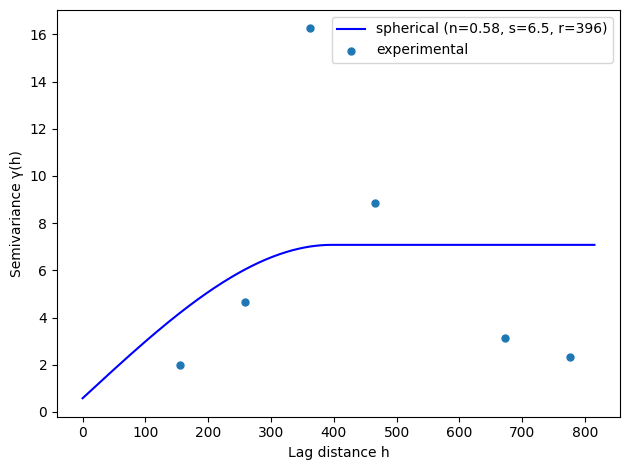

In [5]:
path_points = parent_path/"sensor_locations.json"
points = pd.read_json(path_points)
print(points)

names = ["Boston Carter Field", "Boston Gainsborough Parking Garage", "Boston Robinson Hall", "Boston West Village B", "Boston World Series Way"]

points_list = [(float(points[points["sensor_name"] == name]["longitude"].values[0]), float(points[points["sensor_name"] == name]["latitude"].values[0])) for name in names]
boston_crs = "EPSG:26986"
from pyproj import Transformer

transformer = Transformer.from_crs("EPSG:4326", "EPSG:26986", always_xy=True)
transformed_points = [transformer.transform(lon, lat) for lon, lat in points_list]

from variogram_training import  fit_variogram_model

variogram_model = fit_variogram_model(
    points = transformed_points,
    values = measurements_at_timestamp.values
)

print("Fitted variogram model parameters:")
print(variogram_model)

from variogram_training import plot_variogram_fit

plot_variogram_fit(
    variogram_model
)



In [ ]:
import geopandas as gpd

grid_rectangles = gpd.read_file(DATA_DIR / "spatial" / "grid_rectangles.geojson")
grid_centroids = [(geom.centroid.x, geom.centroid.y) for geom in grid_rectangles.geometry]

from src.kriging.variogram_training import ordinary_kriging_predict

predictions = ordinary_kriging_predict(
    points=transformed_points,
    values=list(measurements_at_timestamp.values),
    fit=variogram_model,
    query_points=grid_centroids,
)

In [7]:
predictions

array([25.88977716, 25.88977716, 25.88977716, 25.88977716, 25.88977716,
       25.88977716, 25.88977716, 25.88977716, 25.88977716, 25.88977716,
       25.88977716, 25.88977716, 25.88977716, 25.88977716, 25.88977716,
       25.88977716, 25.88977716, 25.88977716, 25.88977716, 25.88977716,
       25.88977716, 25.88977716, 25.88977716, 25.88977716, 25.88977716,
       25.88977716, 25.88977716, 25.88977716, 25.88977716, 25.88977716,
       25.88977716, 25.88977716, 25.88977716, 25.88977716, 25.88977716,
       25.88977716, 25.88977716, 25.88977716, 25.88977716, 25.88977716,
       25.88977716, 25.88977716, 25.88977716, 25.88977716, 25.88977716,
       25.88977716, 25.88977716, 25.88977716, 25.88977716, 25.88977716,
       25.88977716, 25.88977716, 25.88977716, 25.88977716, 25.88977716,
       25.88977716, 25.88977716, 25.88977716, 25.88977716, 25.88977716,
       25.88977716, 25.88977716, 25.88977716, 25.88977716, 25.88977716,
       25.88977716, 25.88977716, 25.88977716, 25.88977716, 25.88

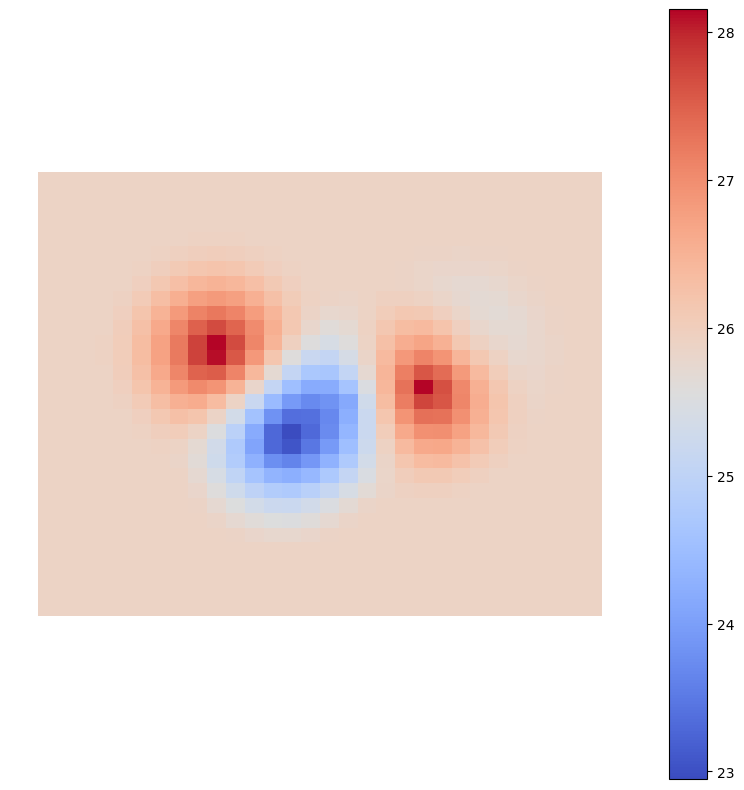

In [8]:
fig, ax = plt.subplots(figsize=(10, 10))

grid_rectangles["predicted_temperature"] = predictions
grid_rectangles.plot(column="predicted_temperature", cmap="coolwarm", legend=True, ax=ax)
ax.set_axis_off()

In [9]:
variogram_model

{'model': 'spherical',
 'nugget': 0.5802566997419646,
 'sill': 6.498875037110004,
 'range': 396.4498930865388,
 'score_mse': 22.213375331304235,
 'lag_centers': [155.20359825503238,
  258.6726637583873,
  362.14172926174217,
  465.6107947650971,
  672.5489257718069,
  776.0179912751619],
 'experimental_semivariance': [1.968386613308563,
  4.678427161728802,
  16.24718759277501,
  8.831864962710485,
  3.1366093851385397,
  2.3388468564439755],
 'fitted_semivariance': [4.201598979770224,
  6.038163761881233,
  7.008233437130495,
  7.079131736851968,
  7.079131736851968,
  7.079131736851968]}